In [7]:
pip install torch torchvision torchaudio

  Using cached torch-2.12.0-cp311-cp311-macosx_14_0_arm64.whl.metadata (31 kB)
  Using cached torchvision-0.27.0-cp311-cp311-macosx_14_0_arm64.whl.metadata (5.5 kB)
  Using cached torchaudio-2.11.0-cp311-cp311-macosx_11_0_arm64.whl.metadata (6.9 kB)
  Using cached filelock-3.29.0-py3-none-any.whl.metadata (2.0 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached fsspec-2026.4.0-py3-none-any.whl.metadata (10 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
Using cached torch-2.12.0-cp311-cp311-macosx_14_0_arm64.whl (88.0 MB)
Using cached torchvision-0.27.0-cp311-cp311-macosx_14_0_arm64.whl (1.8 MB)
Using cached torchaudio-2.11.0-cp311-cp311-macosx_11_0_arm64.whl (684 kB)
Using cached fsspec-2026.4.0-py3-none-any.whl (203 kB)
Using cached networkx-3.6.1-py3-none-any.whl (2.1 MB)
Using cached sympy-1.14.0-py3-none-any.whl (6.3 MB)
Using cached mpmath-1.3.0-py3-none-any.whl (536 k

In [1]:
!pip install torch torchvision scikit-learn pandas numpy matplotlib seaborn plotly
!pip install flask-ngrok pyngrok ipywidgets


import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, random_split
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px

from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

import pickle
import json
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

print("✅ All packages installed successfully!")


[notice] A new release of pip is available: 25.3 -> 26.1.1
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 25.3 -> 26.1.1
[notice] To update, run: pip install --upgrade pip
✅ All packages installed successfully!


In [2]:
import os

directories = [
    'data',
    'models',
    'logs',
    'visualizations',
    'results'
]

for directory in directories:
    os.makedirs(directory, exist_ok=True)
    print(f"📁 Created directory: {directory}")

print("\n✅ Project structure created!")

📁 Created directory: data
📁 Created directory: models
📁 Created directory: logs
📁 Created directory: visualizations
📁 Created directory: results

✅ Project structure created!


In [3]:
class SimpleModel(nn.Module):
    """
    Simple Convolutional Neural Network for MNIST
    This represents what each participant (hospital/bank) trains locally
    """
    def __init__(self):
        super(SimpleModel, self).__init__()

        
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)

        
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

        
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))

        
        x = x.view(-1, 64 * 7 * 7)

        
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x


model = SimpleModel()
print("✅ Model architecture:")
print(model)
print(f"\nTotal parameters: {sum(p.numel() for p in model.parameters())}")

✅ Model architecture:
SimpleModel(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
)

Total parameters: 421642


📥 Downloading MNIST dataset...
✅ Training samples: 60000
✅ Test samples: 10000


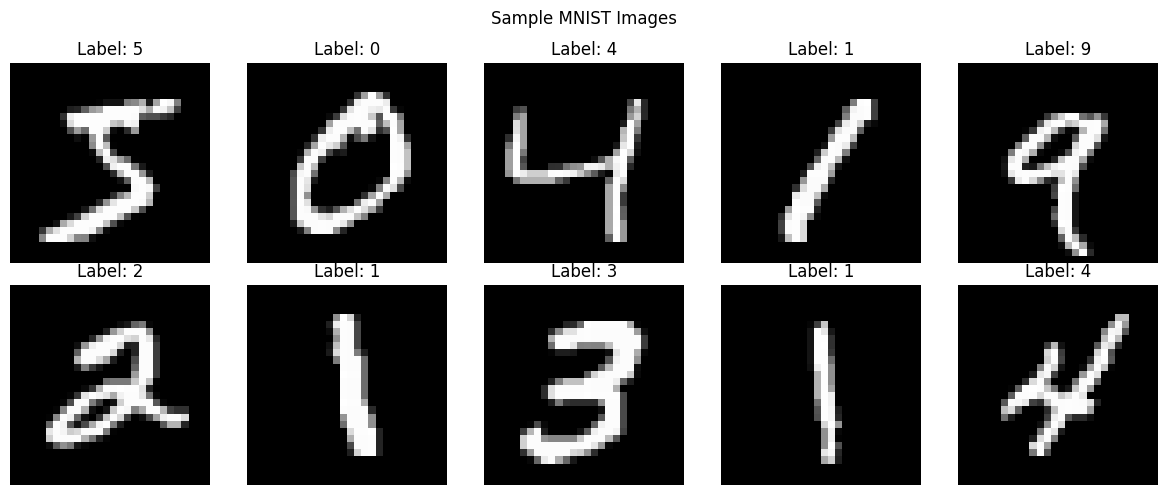

In [4]:
print("📥 Downloading MNIST dataset...")


transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])


train_dataset = datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

print(f"✅ Training samples: {len(train_dataset)}")
print(f"✅ Test samples: {len(test_dataset)}")


fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    ax.imshow(image.squeeze(), cmap='gray')
    ax.set_title(f'Label: {label}')
    ax.axis('off')
plt.suptitle('Sample MNIST Images')
plt.tight_layout()
plt.savefig('visualizations/mnist_samples.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
def split_dataset_for_clients(dataset, num_clients=10):
    """
    Split dataset among multiple clients
    Simulates federated learning scenario
    """
    total_size = len(dataset)
    sizes = [total_size // num_clients] * num_clients

    
    remainder = total_size % num_clients
    for i in range(remainder):
        sizes[i] += 1

    return random_split(dataset, sizes)

def train_and_collect_gradients(client_id, client_data, epochs=1):
    """
    Train model locally and collect gradients
    This simulates what a legitimate participant does
    """
    model = SimpleModel()
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)

    
    dataloader = DataLoader(client_data, batch_size=32, shuffle=True)

    gradient_list = []

    for epoch in range(epochs):
        for batch_idx, (data, target) in enumerate(dataloader):
            
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, target)

            
            loss.backward()

            gradients = {}
            for name, param in model.named_parameters():
                if param.grad is not None:
                    gradients[name] = param.grad.clone().detach().cpu().numpy()

            gradient_list.append({
                'client_id': client_id,
                'batch': batch_idx,
                'epoch': epoch,
                'gradients': gradients,
                'loss': loss.item()
            })

            optimizer.step()

            if batch_idx >= 10:
                break

    return gradient_list

print("🔄 Simulating Collaborative Learning...")
print("=" * 60)

num_clients = 10
client_datasets = split_dataset_for_clients(train_dataset, num_clients)

all_normal_gradients = []

for client_id in range(num_clients):
    print(f"Training Client {client_id + 1}/{num_clients}...", end=" ")

    client_gradients = train_and_collect_gradients(
        client_id=f"client_{client_id}",
        client_data=client_datasets[client_id],
        epochs=1
    )

    all_normal_gradients.extend(client_gradients)
    print(f"✅ Collected {len(client_gradients)} gradient samples")

print(f"\n✅ Total NORMAL gradients collected: {len(all_normal_gradients)}")

🔄 Simulating Collaborative Learning...
Training Client 1/10... ✅ Collected 11 gradient samples
Training Client 2/10... ✅ Collected 11 gradient samples
Training Client 3/10... ✅ Collected 11 gradient samples
Training Client 4/10... ✅ Collected 11 gradient samples
Training Client 5/10... ✅ Collected 11 gradient samples
Training Client 6/10... ✅ Collected 11 gradient samples
Training Client 7/10... ✅ Collected 11 gradient samples
Training Client 8/10... ✅ Collected 11 gradient samples
Training Client 9/10... ✅ Collected 11 gradient samples
Training Client 10/10... ✅ Collected 11 gradient samples

✅ Total NORMAL gradients collected: 110


In [ ]:
class SimpleGAN(nn.Module):
    """
    Simple GAN for simulating gradient manipulation attack
    Adversary uses this to try reconstructing private data
    """
    def __init__(self, latent_dim=100):
        super(SimpleGAN, self).__init__()

        self.generator = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 28*28),
            nn.Tanh()
        )

        self.discriminator = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )

        self.latent_dim = latent_dim

    def generate(self, num_samples):
        noise = torch.randn(num_samples, self.latent_dim)
        return self.generator(noise)

def generate_malicious_gradients(num_samples=100):
    """
    Simulate GAN-based gradient manipulation attack
    Adversary manipulates gradients to help GAN reconstruct data
    """
    print("🔴 Simulating GAN-based ATTACK...")

    gan = SimpleGAN()
    target_model = SimpleModel()

    criterion = nn.MSELoss()
    optimizer_g = optim.Adam(gan.generator.parameters(), lr=0.0002)
    optimizer_d = optim.Adam(gan.discriminator.parameters(), lr=0.0002)

    malicious_gradients = []

    dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    real_data, _ = next(iter(dataloader))
    real_data = real_data.view(real_data.size(0), -1)

    for iteration in range(num_samples):

        optimizer_g.zero_grad()
        optimizer_d.zero_grad()


        fake_data = gan.generate(32)

        real_pred = gan.discriminator(real_data)
        fake_pred = gan.discriminator(fake_data.detach())
        d_loss = -torch.mean(torch.log(real_pred) + torch.log(1 - fake_pred))

        fake_pred_for_g = gan.discriminator(fake_data)
        g_loss = -torch.mean(torch.log(fake_pred_for_g))

        g_loss.backward()

        gradients = {}
        for name, param in target_model.named_parameters():
            if param.grad is not None:
                manipulated_grad = param.grad.clone().detach().cpu().numpy()
            else:
                shape = param.shape
                manipulated_grad = np.random.randn(*shape) * 10.0  

                manipulated_grad += np.random.exponential(2.0, shape) 

            gradients[name] = manipulated_grad

        malicious_gradients.append({
            'client_id': 'adversary',
            'batch': iteration,
            'epoch': 0,
            'gradients': gradients,
            'loss': g_loss.item(),
            'attack_type': 'GAN_inversion'
        })

        if (iteration + 1) % 20 == 0:
            print(f"  Generated {iteration + 1}/{num_samples} malicious gradients")

    print(f"✅ Total MALICIOUS gradients generated: {len(malicious_gradients)}")
    return malicious_gradients

all_malicious_gradients = generate_malicious_gradients(num_samples=100)

🔴 Simulating GAN-based ATTACK...
  Generated 20/100 malicious gradients
  Generated 40/100 malicious gradients
  Generated 60/100 malicious gradients
  Generated 80/100 malicious gradients
  Generated 100/100 malicious gradients
✅ Total MALICIOUS gradients generated: 100


In [7]:
print("🏷️ Labeling gradient samples...")


for grad in all_normal_gradients:
    grad['label'] = 0 

for grad in all_malicious_gradients:
    grad['label'] = 1

all_gradients = all_normal_gradients + all_malicious_gradients

np.random.shuffle(all_gradients)

print(f"✅ Total dataset size: {len(all_gradients)}")
print(f"   - Normal samples: {sum(1 for g in all_gradients if g['label'] == 0)}")
print(f"   - Malicious samples: {sum(1 for g in all_gradients if g['label'] == 1)}")

with open('data/raw_gradients.pkl', 'wb') as f:
    pickle.dump(all_gradients, f)

print("💾 Raw gradients saved to 'data/raw_gradients.pkl'")

🏷️ Labeling gradient samples...
✅ Total dataset size: 210
   - Normal samples: 110
   - Malicious samples: 100
💾 Raw gradients saved to 'data/raw_gradients.pkl'


In [8]:
class GradientFeatureExtractor:
    """
    Extract statistical features from gradients
    These features help identify malicious patterns
    """

    def __init__(self):
        self.scaler = StandardScaler()
        self.feature_names = []

    def extract_single_gradient_features(self, gradient_array):
        """
        Extract features from a single gradient array
        """
        flat = gradient_array.flatten()

        features = [
            np.mean(flat),                          
            np.std(flat),                          
            np.var(flat),                           
            np.min(flat),                           
            np.max(flat),                            
            np.median(flat),                       
            np.percentile(flat, 25),                
            np.percentile(flat, 75),               


            self._skewness(flat),                  
            self._kurtosis(flat),                    

            np.linalg.norm(flat, 1),                 
            np.linalg.norm(flat, 2),               
            np.linalg.norm(flat, np.inf),         

            self._sparsity(flat),                  


            self._entropy(flat),                    

            np.max(flat) - np.min(flat),           

            np.sum(flat > 0),                    
            np.sum(flat < 0),                       
            np.sum(np.abs(flat) < 1e-6),      
        ]

        return np.array(features)

    def extract_features_from_gradient_dict(self, gradient_dict):
        """
        Extract features from all layers in gradient dictionary
        """
        all_layer_features = []

        for layer_name, grad_array in gradient_dict.items():
            layer_features = self.extract_single_gradient_features(grad_array)
            all_layer_features.extend(layer_features)

        layer_norms = [np.linalg.norm(g.flatten()) for g in gradient_dict.values()]
        cross_layer_features = [
            np.mean(layer_norms),                  
            np.std(layer_norms),                    
            np.max(layer_norms) / (np.min(layer_norms) + 1e-10), 
        ]

        all_layer_features.extend(cross_layer_features)

        return np.array(all_layer_features)

    def _skewness(self, data):
        """Calculate skewness"""
        mean = np.mean(data)
        std = np.std(data)
        if std == 0:
            return 0
        return np.mean(((data - mean) / std) ** 3)

    def _kurtosis(self, data):
        """Calculate kurtosis"""
        mean = np.mean(data)
        std = np.std(data)
        if std == 0:
            return 0
        return np.mean(((data - mean) / std) ** 4) - 3

    def _sparsity(self, data, threshold=1e-6):
        """Calculate sparsity (percentage of near-zero values)"""
        return np.sum(np.abs(data) < threshold) / len(data)

    def _entropy(self, data, bins=50):
        """Calculate Shannon entropy"""
        hist, _ = np.histogram(data, bins=bins)
        hist = hist + 1e-10  # Avoid log(0)
        hist = hist / hist.sum()
        entropy = -np.sum(hist * np.log(hist))
        return entropy

    def fit_transform(self, gradient_list):
        """
        Extract features from list of gradients and normalize
        """
        print("🔍 Extracting features from gradients...")

        X = []
        y = []

        for i, gradient_sample in enumerate(gradient_list):
            try:
                features = self.extract_features_from_gradient_dict(
                    gradient_sample['gradients']
                )
                X.append(features)
                y.append(gradient_sample['label'])

                if (i + 1) % 50 == 0:
                    print(f"  Processed {i + 1}/{len(gradient_list)} samples")

            except Exception as e:
                print(f"  ⚠️ Error processing sample {i}: {e}")
                continue

        X = np.array(X)
        y = np.array(y)

        print(f"✅ Feature extraction complete!")
        print(f"   Feature matrix shape: {X.shape}")
        print(f"   Number of features per sample: {X.shape[1]}")

       
        X_normalized = self.scaler.fit_transform(X)

        return X_normalized, y

    def transform(self, gradient_list):
        """Transform new gradients using fitted scaler"""
        X = []
        for gradient_sample in gradient_list:
            features = self.extract_features_from_gradient_dict(
                gradient_sample['gradients']
            )
            X.append(features)

        X = np.array(X)
        X_normalized = self.scaler.transform(X)
        return X_normalized

feature_extractor = GradientFeatureExtractor()

print("✅ Feature Extractor initialized!")

✅ Feature Extractor initialized!


In [9]:
with open('data/raw_gradients.pkl', 'rb') as f:
    all_gradients = pickle.load(f)

print(f"📊 Loaded {len(all_gradients)} gradient samples")


X, y = feature_extractor.fit_transform(all_gradients)

print(f"\n📈 Feature Statistics:")
print(f"   Shape: {X.shape}")
print(f"   Normal samples (y=0): {np.sum(y == 0)}")
print(f"   Malicious samples (y=1): {np.sum(y == 1)}")
print(f"   Class balance: {np.sum(y == 1) / len(y) * 100:.1f}% malicious")


np.save('data/features_X.npy', X)
np.save('data/labels_y.npy', y)
pickle.dump(feature_extractor, open('models/feature_extractor.pkl', 'wb'))

print("\n💾 Saved:")
print("   - features_X.npy")
print("   - labels_y.npy")
print("   - feature_extractor.pkl")

📊 Loaded 210 gradient samples
🔍 Extracting features from gradients...
  Processed 50/210 samples
  Processed 100/210 samples
  Processed 150/210 samples
  Processed 200/210 samples
✅ Feature extraction complete!
   Feature matrix shape: (210, 155)
   Number of features per sample: 155

📈 Feature Statistics:
   Shape: (210, 155)
   Normal samples (y=0): 110
   Malicious samples (y=1): 100
   Class balance: 47.6% malicious

💾 Saved:
   - features_X.npy
   - labels_y.npy
   - feature_extractor.pkl


📊 Visualizing feature distributions...


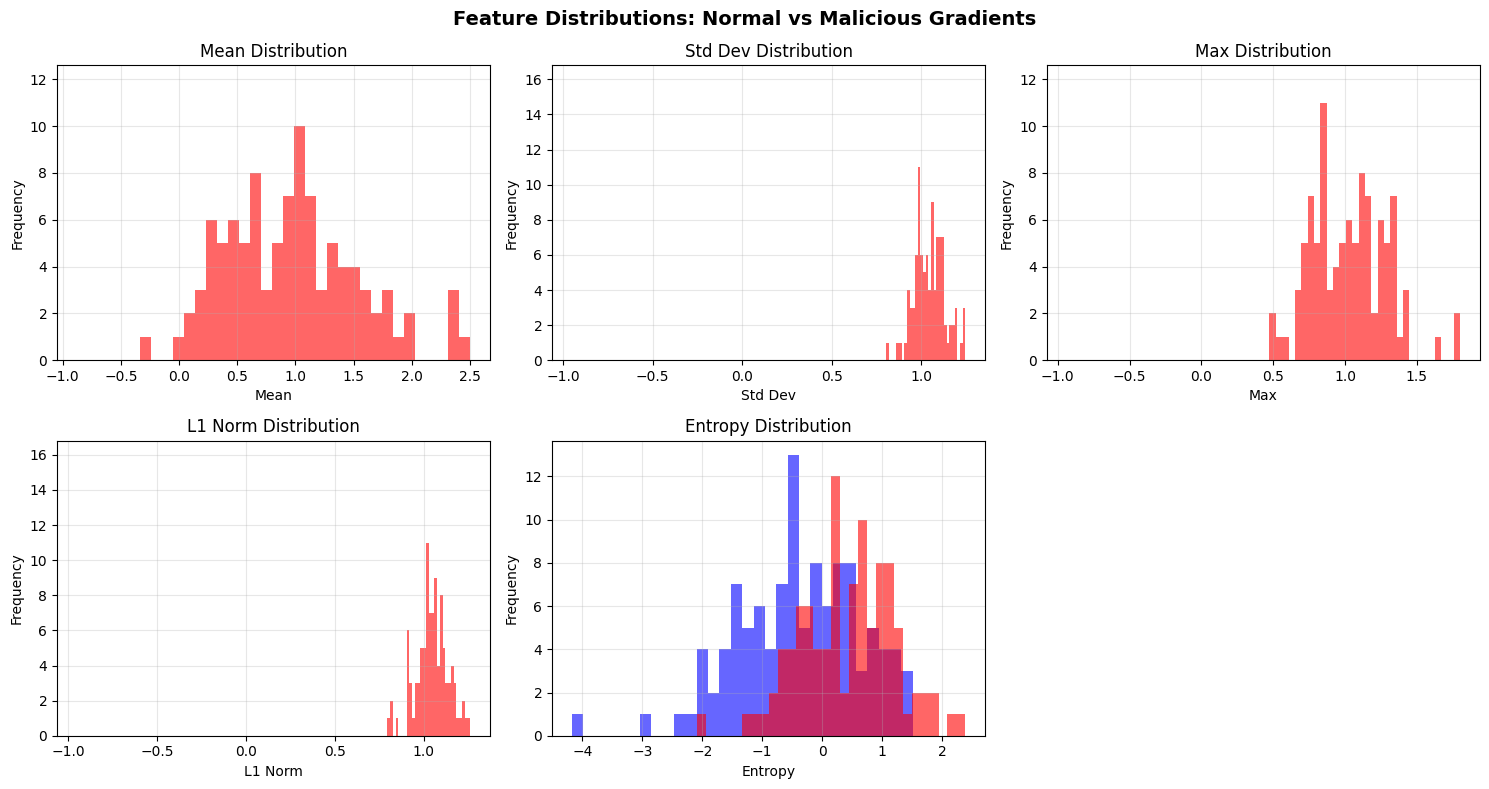

✅ Visualization saved to 'visualizations/feature_distributions.png'


In [10]:

print("📊 Visualizing feature distributions...")

feature_indices = [0, 1, 4, 10, 14] 
feature_names = ['Mean', 'Std Dev', 'Max', 'L1 Norm', 'Entropy']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for idx, (feat_idx, feat_name) in enumerate(zip(feature_indices, feature_names)):
    ax = axes[idx]

    normal_values = X[y == 0, feat_idx]
    malicious_values = X[y == 1, feat_idx]

    ax.hist(normal_values, bins=30, alpha=0.6, label='Normal', color='blue')
    ax.hist(malicious_values, bins=30, alpha=0.6, label='Malicious', color='red')

    ax.set_xlabel(feat_name)
    ax.set_ylabel('Frequency')
    ax.set_title(f'{feat_name} Distribution')
    ax.grid(True, alpha=0.3)

axes[-1].remove()

plt.suptitle('Feature Distributions: Normal vs Malicious Gradients', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('visualizations/feature_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ Visualization saved to 'visualizations/feature_distributions.png'")

In [11]:
from sklearn.metrics import precision_recall_curve, average_precision_score

class AnomalyDetector:
    """
    Anomaly Detection System for GAN-based attacks
    """

    def __init__(self, algorithm='isolation_forest', contamination=0.1):
        self.algorithm = algorithm
        self.contamination = contamination
        self.model = None
        self.threshold = None
        self.training_history = {}

    def train(self, X_train, y_train):
        """
        Train anomaly detector
        """
        print(f"🎯 Training {self.algorithm} detector...")
        print("=" * 60)

        if self.algorithm == 'isolation_forest':
            self.model = IsolationForest(
                n_estimators=100,
                contamination=self.contamination,
                random_state=42,
                n_jobs=-1,
                verbose=1
            )

        elif self.algorithm == 'one_class_svm':
            self.model = OneClassSVM(
                kernel='rbf',
                gamma='auto',
                nu=self.contamination
            )

        X_normal = X_train[y_train == 0]

        print(f"Training on {len(X_normal)} normal samples...")
        self.model.fit(X_normal)

        scores = self.model.score_samples(X_train)
        self.threshold = np.percentile(scores, self.contamination * 100)

        print(f"✅ Model trained successfully!")
        print(f"   Decision threshold: {self.threshold:.4f}")

        self.training_history = {
            'n_samples': len(X_normal),
            'contamination': self.contamination,
            'threshold': self.threshold,
            'timestamp': datetime.now().isoformat()
        }

    def predict(self, X):
        """
        Predict: 0 = normal, 1 = anomaly (malicious)
        """
        predictions = self.model.predict(X)
        return (predictions == -1).astype(int)

    def score_samples(self, X):
        """
        Get anomaly scores (lower = more anomalous)
        """
        return self.model.score_samples(X)

    def evaluate(self, X_test, y_test):
        """
        Comprehensive evaluation
        """
        print("\n📊 EVALUATING DETECTION SYSTEM")
        print("=" * 60)

        # Predictions
        y_pred = self.predict(X_test)
        scores = self.score_samples(X_test)

        # Confusion Matrix
        cm = confusion_matrix(y_test, y_pred)
        print("\n📋 Confusion Matrix:")
        print(cm)

        tn, fp, fn, tp = cm.ravel()

        print(f"\n   True Negatives (TN):  {tn} (Normal correctly identified)")
        print(f"   False Positives (FP): {fp} (Normal flagged as malicious)")
        print(f"   False Negatives (FN): {fn} (Malicious missed)")
        print(f"   True Positives (TP):  {tp} (Malicious correctly detected)")

        # Metrics
        accuracy = (tp + tn) / (tp + tn + fp + fn)
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

        print(f"\n📈 Performance Metrics:")
        print(f"   Accuracy:  {accuracy:.4f} ({accuracy*100:.2f}%)")
        print(f"   Precision: {precision:.4f} ({precision*100:.2f}%)")
        print(f"   Recall:    {recall:.4f} ({recall*100:.2f}%)")
        print(f"   F1-Score:  {f1:.4f}")
        print(f"   False Positive Rate: {fpr:.4f} ({fpr*100:.2f}%)")

        print(f"\n📑 Detailed Classification Report:")
        print(classification_report(y_test, y_pred,
                                     target_names=['Normal', 'Malicious']))

        fpr_curve, tpr_curve, thresholds = roc_curve(y_test, -scores)
        roc_auc = auc(fpr_curve, tpr_curve)

        print(f"\n🎯 ROC AUC Score: {roc_auc:.4f}")

        return {
            'accuracy': accuracy,
            'precision': precision,
            'recall': recall,
            'f1_score': f1,
            'fpr': fpr,
            'roc_auc': roc_auc,
            'confusion_matrix': cm,
            'predictions': y_pred,
            'scores': scores
        }

    def save(self, path='models/detector.pkl'):
        """Save trained detector"""
        pickle.dump(self, open(path, 'wb'))
        print(f"💾 Detector saved to {path}")

    @staticmethod
    def load(path='models/detector.pkl'):
        """Load trained detector"""
        return pickle.load(open(path, 'rb'))


detector = AnomalyDetector(algorithm='isolation_forest', contamination=0.15)


X = np.load('data/features_X.npy')
y = np.load('data/labels_y.npy')


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"📊 Data Split:")
print(f"   Training: {len(X_train)} samples")
print(f"   Testing:  {len(X_test)} samples")
print()


detector.train(X_train, y_train)

results = detector.evaluate(X_test, y_test)

detector.save('models/detector.pkl')

📊 Data Split:
   Training: 147 samples
   Testing:  63 samples

🎯 Training isolation_forest detector...
Training on 77 normal samples...
✅ Model trained successfully!
   Decision threshold: -0.7114

📊 EVALUATING DETECTION SYSTEM

📋 Confusion Matrix:
[[26  7]
 [ 0 30]]

   True Negatives (TN):  26 (Normal correctly identified)
   False Positives (FP): 7 (Normal flagged as malicious)
   False Negatives (FN): 0 (Malicious missed)
   True Positives (TP):  30 (Malicious correctly detected)

📈 Performance Metrics:
   Accuracy:  0.8889 (88.89%)
   Precision: 0.8108 (81.08%)
   Recall:    1.0000 (100.00%)
   F1-Score:  0.8955
   False Positive Rate: 0.2121 (21.21%)

📑 Detailed Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.79      0.88        33
   Malicious       0.81      1.00      0.90        30

    accuracy                           0.89        63
   macro avg       0.91      0.89      0.89        63
weighted avg       0.91    

[Parallel(n_jobs=10)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done   2 out of  10 | elapsed:    0.1s remaining:    0.4s
[Parallel(n_jobs=10)]: Done  10 out of  10 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished


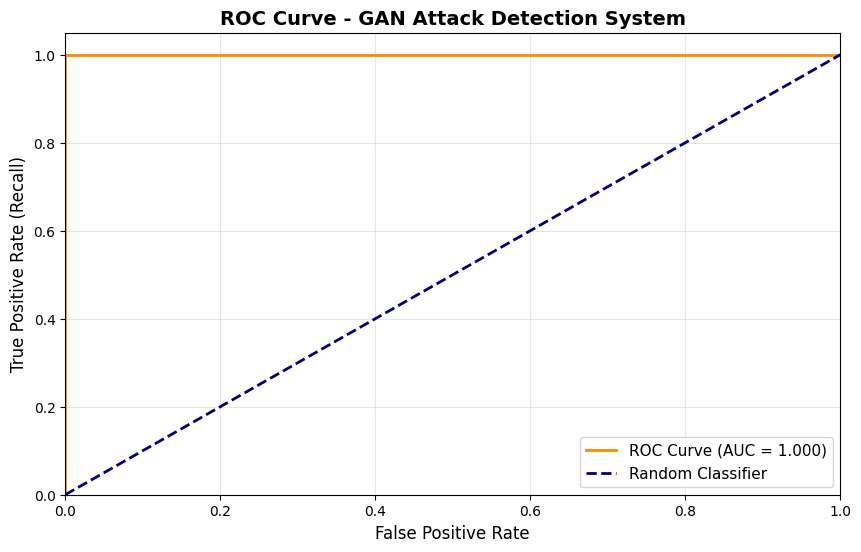

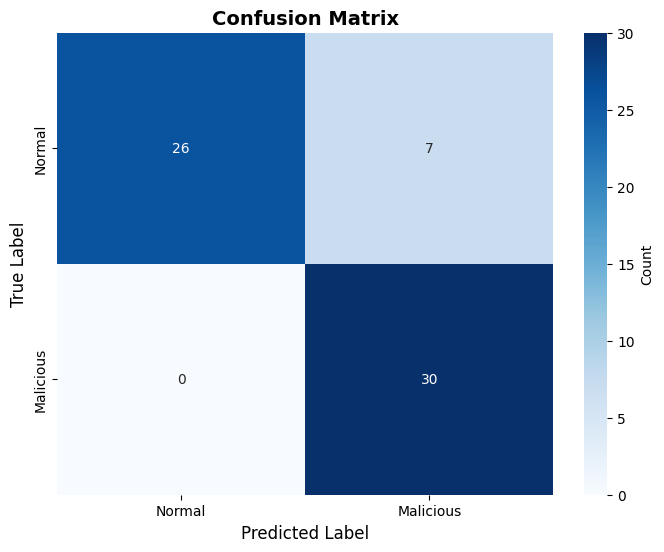

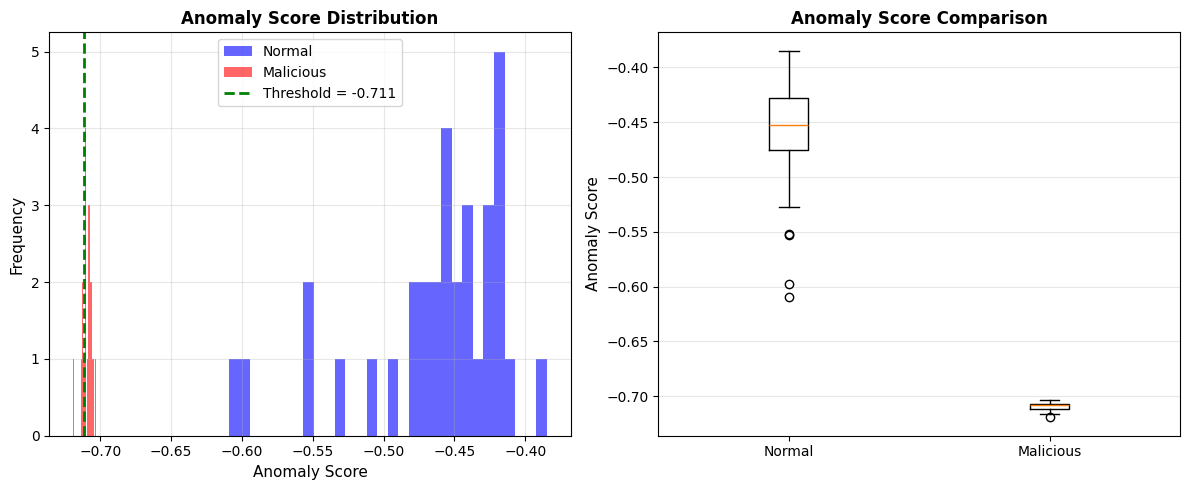

✅ All visualizations saved!


In [12]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, -results['scores'])
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2,
         label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate (Recall)', fontsize=12)
plt.title('ROC Curve - GAN Attack Detection System', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, alpha=0.3)
plt.savefig('visualizations/roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(results['confusion_matrix'], annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Malicious'],
            yticklabels=['Normal', 'Malicious'],
            cbar_kws={'label': 'Count'})
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
plt.savefig('visualizations/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
normal_scores = results['scores'][y_test == 0]
malicious_scores = results['scores'][y_test == 1]

plt.hist(normal_scores, bins=30, alpha=0.6, label='Normal', color='blue')
plt.hist(malicious_scores, bins=30, alpha=0.6, label='Malicious', color='red')
plt.axvline(detector.threshold, color='green', linestyle='--', linewidth=2,
            label=f'Threshold = {detector.threshold:.3f}')
plt.xlabel('Anomaly Score', fontsize=11)
plt.ylabel('Frequency', fontsize=11)
plt.title('Anomaly Score Distribution', fontsize=12, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.boxplot([normal_scores, malicious_scores], labels=['Normal', 'Malicious'])
plt.ylabel('Anomaly Score', fontsize=11)
plt.title('Anomaly Score Comparison', fontsize=12, fontweight='bold')
plt.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('visualizations/anomaly_scores.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ All visualizations saved!")

In [13]:
class RealTimeDetectionSystem:
    """
    Simulates real-time gradient monitoring and attack detection
    """

    def __init__(self, detector, feature_extractor):
        self.detector = detector
        self.feature_extractor = feature_extractor
        self.detection_logs = []
        self.isolated_clients = set()
        self.client_history = {}

    def process_gradient_submission(self, client_id, gradients, round_num):
        """
        Process a single gradient submission
        Returns: (is_accepted, anomaly_score, decision)
        """
        timestamp = datetime.now()

        if client_id in self.isolated_clients:
            return {
                'accepted': False,
                'reason': 'Client previously isolated',
                'client_id': client_id,
                'timestamp': timestamp.isoformat()
            }

        gradient_sample = {'gradients': gradients}
        features = self.feature_extractor.transform([gradient_sample])

        prediction = self.detector.predict(features)[0]
        anomaly_score = self.detector.score_samples(features)[0]

        is_malicious = (prediction == 1)

        log_entry = {
            'client_id': client_id,
            'round': round_num,
            'timestamp': timestamp.isoformat(),
            'anomaly_score': float(anomaly_score),
            'is_malicious': bool(is_malicious),
            'decision': 'REJECTED' if is_malicious else 'ACCEPTED'
        }

        self.detection_logs.append(log_entry)

        if is_malicious:
            self.isolated_clients.add(client_id)
            print(f"🚨 ALERT: Malicious gradient detected from {client_id}!")
            print(f"   Anomaly Score: {anomaly_score:.4f}")
            print(f"   Action: Client isolated")

            return {
                'accepted': False,
                'reason': 'GAN-based attack detected',
                'client_id': client_id,
                'anomaly_score': anomaly_score,
                'timestamp': timestamp.isoformat()
            }

        if client_id not in self.client_history:
            self.client_history[client_id] = []

        self.client_history[client_id].append({
            'round': round_num,
            'score': anomaly_score,
            'timestamp': timestamp
        })

        return {
            'accepted': True,
            'client_id': client_id,
            'anomaly_score': anomaly_score,
            'timestamp': timestamp.isoformat()
        }

    def get_statistics(self):
        """Get system statistics"""
        total_submissions = len(self.detection_logs)
        malicious_count = sum(1 for log in self.detection_logs if log['is_malicious'])

        return {
            'total_submissions': total_submissions,
            'malicious_detected': malicious_count,
            'normal_accepted': total_submissions - malicious_count,
            'isolated_clients': len(self.isolated_clients),
            'active_clients': len(self.client_history),
            'detection_rate': malicious_count / total_submissions if total_submissions > 0 else 0
        }

    def generate_report(self):
        """Generate detection report"""
        stats = self.get_statistics()

        print("\n" + "="*60)
        print("🛡️  DETECTION SYSTEM REPORT")
        print("="*60)
        print(f"\n📊 Overall Statistics:")
        print(f"   Total Submissions:    {stats['total_submissions']}")
        print(f"   Normal (Accepted):    {stats['normal_accepted']}")
        print(f"   Malicious (Rejected): {stats['malicious_detected']}")
        print(f"   Detection Rate:       {stats['detection_rate']*100:.2f}%")
        print(f"\n👥 Client Status:")
        print(f"   Active Clients:       {stats['active_clients']}")
        print(f"   Isolated Clients:     {stats['isolated_clients']}")

        if self.isolated_clients:
            print(f"\n🚫 Isolated Clients:")
            for client in self.isolated_clients:
                print(f"     - {client}")

        print("\n" + "="*60)

rt_system = RealTimeDetectionSystem(detector, feature_extractor)

print("✅ Real-Time Detection System initialized!")

✅ Real-Time Detection System initialized!


In [14]:
print("🔄 Simulating Real-Time Gradient Monitoring...")
print("="*60)

num_normal_clients = 5
num_malicious_clients = 2
rounds = 10

with open('data/raw_gradients.pkl', 'rb') as f:
    test_gradients = pickle.load(f)

normal_test = [g for g in test_gradients if g['label'] == 0][:50]
malicious_test = [g for g in test_gradients if g['label'] == 1][:20]

print("\n📤 Processing gradient submissions...\n")


for round_num in range(rounds):
    print(f"--- Round {round_num + 1}/{rounds} ---")

    for i in range(num_normal_clients):
        client_id = f"hospital_{i+1}"
        gradient_idx = (round_num * num_normal_clients + i) % len(normal_test)
        gradients = normal_test[gradient_idx]['gradients']

        result = rt_system.process_gradient_submission(client_id, gradients, round_num)

        if result['accepted']:
            print(f"✅ {client_id}: ACCEPTED (score: {result['anomaly_score']:.4f})")
        else:
            print(f"❌ {client_id}: REJECTED - {result['reason']}")


    if round_num >= 3:
        for i in range(num_malicious_clients):
            client_id = f"adversary_{i+1}"
            gradient_idx = ((round_num - 3) * num_malicious_clients + i) % len(malicious_test)
            gradients = malicious_test[gradient_idx]['gradients']

            result = rt_system.process_gradient_submission(client_id, gradients, round_num)

            if not result['accepted']:
                print(f"🔴 {client_id}: REJECTED - {result['reason']} (score: {result.get('anomaly_score', 'N/A')})")

    print()

rt_system.generate_report()

with open('logs/detection_logs.json', 'w') as f:
    json.dump(rt_system.detection_logs, f, indent=2)

print("\n💾 Detection logs saved to 'logs/detection_logs.json'")

🔄 Simulating Real-Time Gradient Monitoring...

📤 Processing gradient submissions...

--- Round 1/10 ---
✅ hospital_1: ACCEPTED (score: -0.4312)
🚨 ALERT: Malicious gradient detected from hospital_2!
   Anomaly Score: -0.6094
   Action: Client isolated
❌ hospital_2: REJECTED - GAN-based attack detected
🚨 ALERT: Malicious gradient detected from hospital_3!
   Anomaly Score: -0.5064
   Action: Client isolated
❌ hospital_3: REJECTED - GAN-based attack detected


[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: 

✅ hospital_4: ACCEPTED (score: -0.4080)
✅ hospital_5: ACCEPTED (score: -0.4509)

--- Round 2/10 ---
✅ hospital_1: ACCEPTED (score: -0.3979)
❌ hospital_2: REJECTED - Client previously isolated
❌ hospital_3: REJECTED - Client previously isolated
✅ hospital_4: ACCEPTED (score: -0.4499)
✅ hospital_5: ACCEPTED (score: -0.3922)

--- Round 3/10 ---
🚨 ALERT: Malicious gradient detected from hospital_1!
   Anomaly Score: -0.5142
   Action: Client isolated
❌ hospital_1: REJECTED - GAN-based attack detected
❌ hospital_2: REJECTED - Client previously isolated
❌ hospital_3: REJECTED - Client previously isolated
✅ hospital_4: ACCEPTED (score: -0.4221)
🚨 ALERT: Malicious gradient detected from hospital_5!
   Anomaly Score: -0.5519
   Action: Client isolated
❌ hospital_5: REJECTED - GAN-based attack detected

--- Round 4/10 ---
❌ hospital_1: REJECTED - Client previously isolated
❌ hospital_2: REJECTED - Client previously isolated
❌ hospital_3: REJECTED - Client previously isolated
✅ hospital_4: ACCEPT

[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_j

🚨 ALERT: Malicious gradient detected from adversary_1!
   Anomaly Score: -0.7161
   Action: Client isolated
🔴 adversary_1: REJECTED - GAN-based attack detected (score: -0.7161091721264208)
🚨 ALERT: Malicious gradient detected from adversary_2!
   Anomaly Score: -0.7037
   Action: Client isolated
🔴 adversary_2: REJECTED - GAN-based attack detected (score: -0.7036896543528842)

--- Round 5/10 ---
❌ hospital_1: REJECTED - Client previously isolated
❌ hospital_2: REJECTED - Client previously isolated
❌ hospital_3: REJECTED - Client previously isolated
✅ hospital_4: ACCEPTED (score: -0.4593)
❌ hospital_5: REJECTED - Client previously isolated
🔴 adversary_1: REJECTED - Client previously isolated (score: N/A)
🔴 adversary_2: REJECTED - Client previously isolated (score: N/A)

--- Round 6/10 ---
❌ hospital_1: REJECTED - Client previously isolated
❌ hospital_2: REJECTED - Client previously isolated
❌ hospital_3: REJECTED - Client previously isolated
✅ hospital_4: ACCEPTED (score: -0.4047)
❌ hosp

[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: 

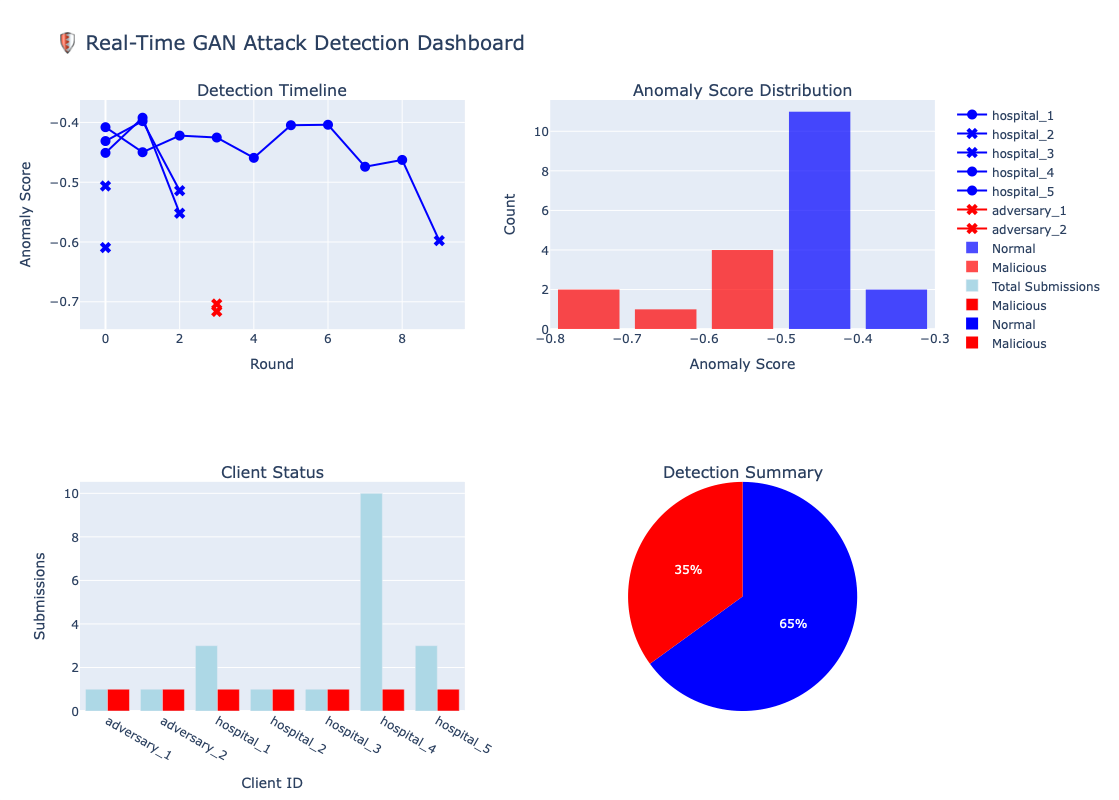

✅ Interactive dashboard created!
💾 Saved to 'visualizations/interactive_dashboard.html'


In [15]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

with open('logs/detection_logs.json', 'r') as f:
    logs = json.load(f)

df_logs = pd.DataFrame(logs)
df_logs['timestamp'] = pd.to_datetime(df_logs['timestamp'])

fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=('Detection Timeline', 'Anomaly Score Distribution',
                    'Client Status', 'Detection Summary'),
    specs=[[{'type': 'scatter'}, {'type': 'histogram'}],
           [{'type': 'bar'}, {'type': 'pie'}]]
)

for client_id in df_logs['client_id'].unique():
    client_data = df_logs[df_logs['client_id'] == client_id]

    color = 'red' if 'adversary' in client_id else 'blue'

    fig.add_trace(
        go.Scatter(
            x=client_data['round'],
            y=client_data['anomaly_score'],
            mode='lines+markers',
            name=client_id,
            line=dict(color=color),
            marker=dict(
                size=10,
                symbol=['x' if m else 'circle' for m in client_data['is_malicious']]
            )
        ),
        row=1, col=1
    )

normal_scores = df_logs[~df_logs['is_malicious']]['anomaly_score']
malicious_scores = df_logs[df_logs['is_malicious']]['anomaly_score']

fig.add_trace(
    go.Histogram(x=normal_scores, name='Normal', marker_color='blue', opacity=0.7),
    row=1, col=2
)
fig.add_trace(
    go.Histogram(x=malicious_scores, name='Malicious', marker_color='red', opacity=0.7),
    row=1, col=2
)

client_stats = df_logs.groupby('client_id').agg({
    'is_malicious': 'sum',
    'round': 'count'
}).reset_index()
client_stats.columns = ['client_id', 'malicious_count', 'total_submissions']

fig.add_trace(
    go.Bar(
        x=client_stats['client_id'],
        y=client_stats['total_submissions'],
        name='Total Submissions',
        marker_color='lightblue'
    ),
    row=2, col=1
)
fig.add_trace(
    go.Bar(
        x=client_stats['client_id'],
        y=client_stats['malicious_count'],
        name='Malicious',
        marker_color='red'
    ),
    row=2, col=1
)

normal_count = len(df_logs[~df_logs['is_malicious']])
malicious_count = len(df_logs[df_logs['is_malicious']])

fig.add_trace(
    go.Pie(
        labels=['Normal', 'Malicious'],
        values=[normal_count, malicious_count],
        marker=dict(colors=['blue', 'red'])
    ),
    row=2, col=2
)

fig.update_layout(
    title_text="🛡️ Real-Time GAN Attack Detection Dashboard",
    title_font_size=20,
    showlegend=True,
    height=800
)

fig.update_xaxes(title_text="Round", row=1, col=1)
fig.update_yaxes(title_text="Anomaly Score", row=1, col=1)
fig.update_xaxes(title_text="Anomaly Score", row=1, col=2)
fig.update_yaxes(title_text="Count", row=1, col=2)
fig.update_xaxes(title_text="Client ID", row=2, col=1)
fig.update_yaxes(title_text="Submissions", row=2, col=1)

# Save and show
fig.write_html('visualizations/interactive_dashboard.html')
fig.show()

print("✅ Interactive dashboard created!")
print("💾 Saved to 'visualizations/interactive_dashboard.html'")

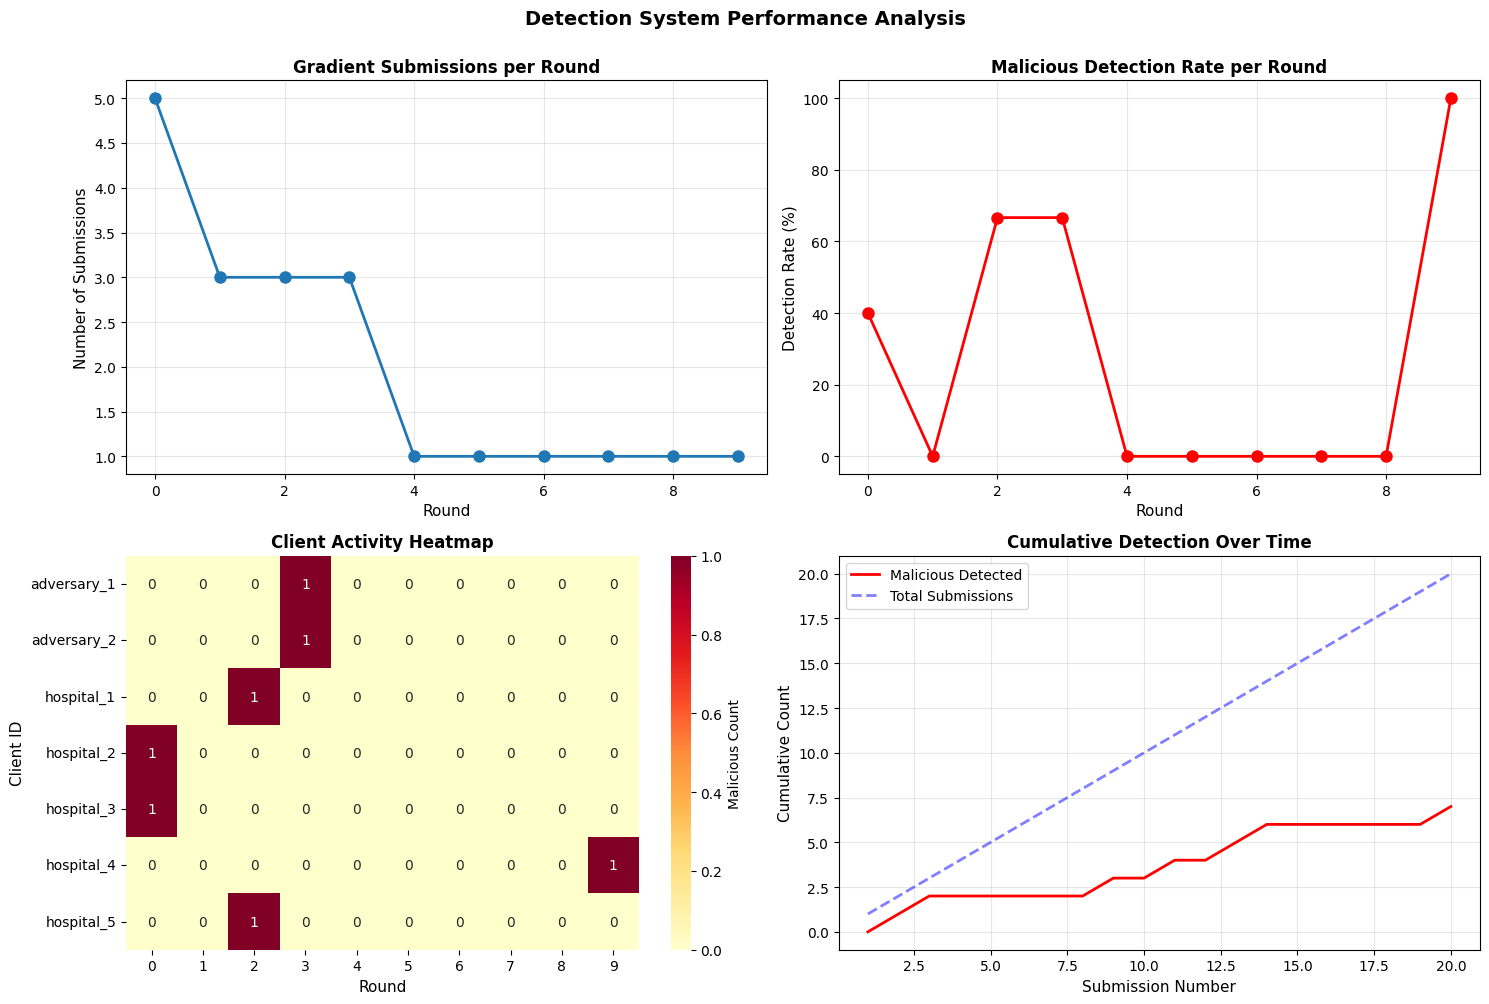

✅ Performance analysis complete!


In [16]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

ax1 = axes[0, 0]
rounds = df_logs.groupby('round').size()
ax1.plot(rounds.index, rounds.values, marker='o', linewidth=2, markersize=8)
ax1.set_xlabel('Round', fontsize=11)
ax1.set_ylabel('Number of Submissions', fontsize=11)
ax1.set_title('Gradient Submissions per Round', fontsize=12, fontweight='bold')
ax1.grid(True, alpha=0.3)

ax2 = axes[0, 1]
detection_by_round = df_logs.groupby('round')['is_malicious'].agg(['sum', 'count'])
detection_rate = (detection_by_round['sum'] / detection_by_round['count'] * 100)
ax2.plot(detection_rate.index, detection_rate.values, marker='o', color='red',
         linewidth=2, markersize=8)
ax2.set_xlabel('Round', fontsize=11)
ax2.set_ylabel('Detection Rate (%)', fontsize=11)
ax2.set_title('Malicious Detection Rate per Round', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3)

ax3 = axes[1, 0]
client_round_matrix = df_logs.pivot_table(
    values='is_malicious',
    index='client_id',
    columns='round',
    aggfunc='sum',
    fill_value=0
)
sns.heatmap(client_round_matrix, annot=True, fmt='g', cmap='YlOrRd',
            cbar_kws={'label': 'Malicious Count'}, ax=ax3)
ax3.set_title('Client Activity Heatmap', fontsize=12, fontweight='bold')
ax3.set_xlabel('Round', fontsize=11)
ax3.set_ylabel('Client ID', fontsize=11)

ax4 = axes[1, 1]
df_logs_sorted = df_logs.sort_values('timestamp')
cumulative_malicious = df_logs_sorted['is_malicious'].cumsum()
cumulative_total = range(1, len(df_logs_sorted) + 1)

ax4.plot(cumulative_total, cumulative_malicious, color='red',
         linewidth=2, label='Malicious Detected')
ax4.plot(cumulative_total, cumulative_total, color='blue',
         linewidth=2, linestyle='--', alpha=0.5, label='Total Submissions')
ax4.set_xlabel('Submission Number', fontsize=11)
ax4.set_ylabel('Cumulative Count', fontsize=11)
ax4.set_title('Cumulative Detection Over Time', fontsize=12, fontweight='bold')
ax4.legend()
ax4.grid(True, alpha=0.3)

plt.suptitle('Detection System Performance Analysis', fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig('visualizations/performance_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ Performance analysis complete!")

In [17]:
class CompleteGANDetectionSystem:
    """
    Complete end-to-end GAN attack detection system
    """

    def __init__(self):
        self.feature_extractor = None
        self.detector = None
        self.rt_system = None
        self.is_initialized = False

    def initialize(self):
        """Initialize all components"""
        print("🚀 Initializing Complete Detection System...")
        print("="*60)

        try:
            self.feature_extractor = pickle.load(open('models/feature_extractor.pkl', 'rb'))
            self.detector = pickle.load(open('models/detector.pkl', 'rb'))
            self.rt_system = RealTimeDetectionSystem(self.detector, self.feature_extractor)

            self.is_initialized = True
            print("✅ System initialized successfully!")
            print(f"   - Feature Extractor: Loaded")
            print(f"   - Anomaly Detector: Loaded")
            print(f"   - Real-Time Monitor: Ready")

        except Exception as e:
            print(f"❌ Initialization failed: {e}")
            self.is_initialized = False

    def detect_gradient(self, client_id, gradients, round_num=0):
        """
        Main detection function - use this to check if gradient is malicious
        """
        if not self.is_initialized:
            raise Exception("System not initialized! Call initialize() first.")

        return self.rt_system.process_gradient_submission(client_id, gradients, round_num)

    def get_system_status(self):
        """Get current system status"""
        if not self.is_initialized:
            return {"status": "not_initialized"}

        stats = self.rt_system.get_statistics()
        stats['status'] = 'operational'
        stats['isolated_clients_list'] = list(self.rt_system.isolated_clients)

        return stats

    def generate_full_report(self):
        """Generate comprehensive system report"""
        if not self.is_initialized:
            print("❌ System not initialized")
            return

        self.rt_system.generate_report()

        self._create_summary_dashboard()

    def save_models(self):
        """Save all trained models"""
        pickle.dump(self.feature_extractor, open('models/feature_extractor.pkl', 'wb'))
        pickle.dump(self.detector, open('models/detector.pkl', 'wb'))
        print("💾 Models saved successfully!")

    def _create_summary_dashboard(self):
        """Create summary visualization"""
        stats = self.get_system_status()

        fig, axes = plt.subplots(2, 2, figsize=(14, 10))

        # System status
        ax1 = axes[0, 0]
        ax1.axis('off')
        status_text = f"""
        SYSTEM STATUS: {stats['status'].upper()}

        📊 STATISTICS:
        ─────────────────────────
        Total Submissions:  {stats['total_submissions']}
        Normal Accepted:    {stats['normal_accepted']}
        Malicious Detected: {stats['malicious_detected']}

        👥 CLIENTS:
        ─────────────────────────
        Active:   {stats['active_clients']}
        Isolated: {stats['isolated_clients']}

        🎯 PERFORMANCE:
        ─────────────────────────
        Detection Rate: {stats['detection_rate']*100:.1f}%
        """
        ax1.text(0.1, 0.5, status_text, fontsize=12, family='monospace',
                verticalalignment='center')
        ax1.set_title('System Status', fontsize=14, fontweight='bold')

        # Detection pie chart
        ax2 = axes[0, 1]
        ax2.pie([stats['normal_accepted'], stats['malicious_detected']],
               labels=['Normal', 'Malicious'],
               colors=['#4CAF50', '#F44336'],
               autopct='%1.1f%%',
               startangle=90)
        ax2.set_title('Detection Distribution', fontsize=14, fontweight='bold')

        ax3 = axes[1, 0]
        if self.rt_system.detection_logs:
            rounds = [log['round'] for log in self.rt_system.detection_logs]
            malicious = [1 if log['is_malicious'] else 0 for log in self.rt_system.detection_logs]

            round_counts = {}
            for r, m in zip(rounds, malicious):
                if r not in round_counts:
                    round_counts[r] = {'normal': 0, 'malicious': 0}
                if m:
                    round_counts[r]['malicious'] += 1
                else:
                    round_counts[r]['normal'] += 1

            rounds_sorted = sorted(round_counts.keys())
            normal_counts = [round_counts[r]['normal'] for r in rounds_sorted]
            malicious_counts = [round_counts[r]['malicious'] for r in rounds_sorted]

            ax3.bar(rounds_sorted, normal_counts, label='Normal', color='#4CAF50', alpha=0.7)
            ax3.bar(rounds_sorted, malicious_counts, bottom=normal_counts,
                   label='Malicious', color='#F44336', alpha=0.7)
            ax3.set_xlabel('Round')
            ax3.set_ylabel('Count')
            ax3.set_title('Submissions per Round', fontsize=14, fontweight='bold')
            ax3.legend()
            ax3.grid(True, alpha=0.3, axis='y')

        ax4 = axes[1, 1]
        client_status = {'Active': stats['active_clients'],
                        'Isolated': stats['isolated_clients']}
        ax4.bar(client_status.keys(), client_status.values(),
               color=['#4CAF50', '#F44336'], alpha=0.7)
        ax4.set_ylabel('Count')
        ax4.set_title('Client Status', fontsize=14, fontweight='bold')
        ax4.grid(True, alpha=0.3, axis='y')

        plt.suptitle('🛡️ GAN Detection System Dashboard',
                    fontsize=16, fontweight='bold')
        plt.tight_layout()
        plt.savefig('visualizations/system_dashboard.png', dpi=150, bbox_inches='tight')
        plt.show()

complete_system = CompleteGANDetectionSystem()

complete_system.initialize()

print("\n✅ Complete system ready!")

🚀 Initializing Complete Detection System...
✅ System initialized successfully!
   - Feature Extractor: Loaded
   - Anomaly Detector: Loaded
   - Real-Time Monitor: Ready

✅ Complete system ready!


🎭 DEMONSTRATION: Testing Detection System

1️⃣ Creating test gradients...
✅ Normal gradient created
✅ Malicious gradient created

2️⃣ Testing detection system...

Testing NORMAL gradient:
🚨 ALERT: Malicious gradient detected from hospital_test!
   Anomaly Score: -0.5518
   Action: Client isolated
   Result: ❌ REJECTED
   Anomaly Score: -0.5517870184783517

Testing MALICIOUS gradient:
🚨 ALERT: Malicious gradient detected from adversary_test!
   Anomaly Score: -0.7108
   Action: Client isolated
   Result: ❌ REJECTED
   Reason: GAN-based attack detected
   Anomaly Score: -0.7107699260440832

Testing submission from ISOLATED client:
   Result: ❌ REJECTED
   Reason: Client previously isolated

3️⃣ Current System Status:
   total_submissions: 2
   malicious_detected: 2
   normal_accepted: 0
   isolated_clients: 2
   active_clients: 0
   detection_rate: 1.0
   status: operational
   isolated_clients_list: ['hospital_test', 'adversary_test']

4️⃣ Generating Final Report...

🛡️  DETECTION SYSTE

[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished


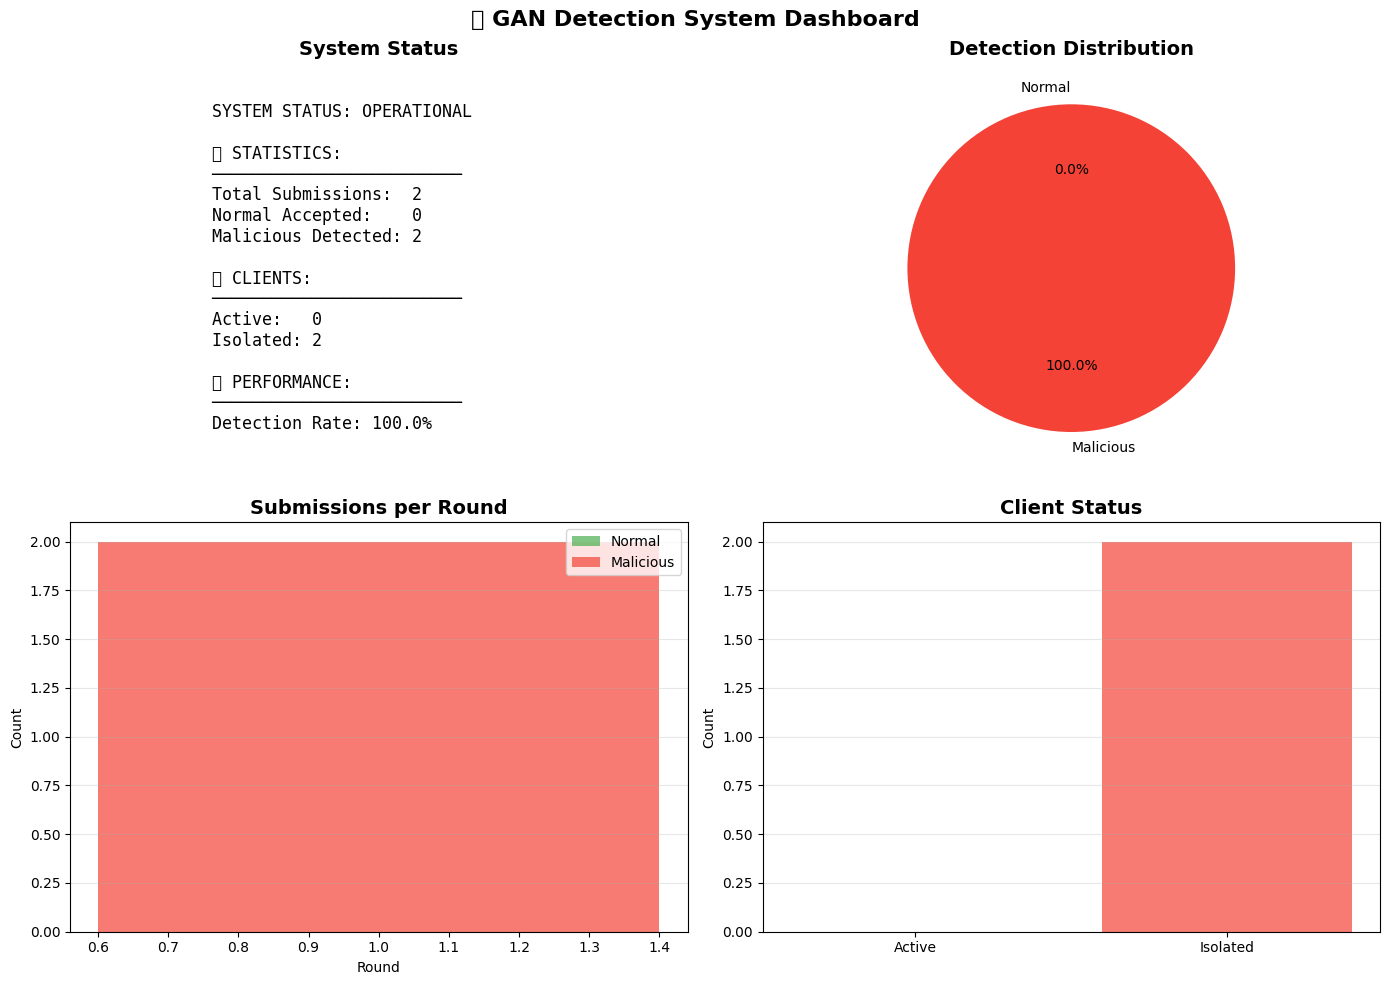


✅ DEMONSTRATION COMPLETE!


In [18]:
print("🎭 DEMONSTRATION: Testing Detection System")
print("="*60)

print("\n1️⃣ Creating test gradients...")

model_normal = SimpleModel()
criterion = nn.CrossEntropyLoss()


test_loader = DataLoader(test_dataset, batch_size=32, shuffle=True)
test_data, test_labels = next(iter(test_loader))

model_normal.zero_grad()
output = model_normal(test_data)
loss = criterion(output, test_labels)
loss.backward()

normal_gradients = {}
for name, param in model_normal.named_parameters():
    if param.grad is not None:
        normal_gradients[name] = param.grad.clone().detach().cpu().numpy()

print("✅ Normal gradient created")

malicious_gradients = {}
for name, param in model_normal.named_parameters():
    shape = param.shape
    mal_grad = np.random.randn(*shape) * 15.0  
    mal_grad += np.random.exponential(3.0, shape) 
    malicious_gradients[name] = mal_grad

print("✅ Malicious gradient created")

print("\n2️⃣ Testing detection system...\n")

print("Testing NORMAL gradient:")
result1 = complete_system.detect_gradient("hospital_test", normal_gradients, round_num=1)
print(f"   Result: {'✅ ACCEPTED' if result1['accepted'] else '❌ REJECTED'}")
print(f"   Anomaly Score: {result1.get('anomaly_score', 'N/A')}")

print("\nTesting MALICIOUS gradient:")
result2 = complete_system.detect_gradient("adversary_test", malicious_gradients, round_num=1)
print(f"   Result: {'✅ ACCEPTED' if result2['accepted'] else '❌ REJECTED'}")
if not result2['accepted']:
    print(f"   Reason: {result2['reason']}")
    print(f"   Anomaly Score: {result2.get('anomaly_score', 'N/A')}")

print("\nTesting submission from ISOLATED client:")
result3 = complete_system.detect_gradient("adversary_test", malicious_gradients, round_num=2)
print(f"   Result: {'✅ ACCEPTED' if result3['accepted'] else '❌ REJECTED'}")
print(f"   Reason: {result3['reason']}")

print("\n3️⃣ Current System Status:")
status = complete_system.get_system_status()
for key, value in status.items():
    print(f"   {key}: {value}")

print("\n4️⃣ Generating Final Report...")
complete_system.generate_full_report()

print("\n✅ DEMONSTRATION COMPLETE!")

In [19]:
import json
from datetime import datetime

config = {
    'project_name': 'GAN Attack Detection System',
    'version': '1.0',
    'created_date': datetime.now().isoformat(),
    'model_type': 'Isolation Forest',
    'feature_count': X.shape[1] if 'X' in locals() else 'N/A',
    'training_samples': len(X) if 'X' in locals() else 'N/A',
    'detection_accuracy': results['accuracy'] if 'results' in locals() else 'N/A',
    'system_status': complete_system.get_system_status() if complete_system.is_initialized else 'Not initialized'
}

with open('results/system_config.json', 'w') as f:
    json.dump(config, f, indent=2)

if 'results' in locals():
    results_to_save = {
        'accuracy': float(results['accuracy']),
        'precision': float(results['precision']),
        'recall': float(results['recall']),
        'f1_score': float(results['f1_score']),
        'roc_auc': float(results['roc_auc']),
        'confusion_matrix': results['confusion_matrix'].tolist()
    }

    with open('results/model_performance.json', 'w') as f:
        json.dump(results_to_save, f, indent=2)

summary = f"""
╔══════════════════════════════════════════════════════════╗
║         GAN ATTACK DETECTION SYSTEM - SUMMARY           ║
╚══════════════════════════════════════════════════════════╝

📅 Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}

📊 MODEL PERFORMANCE:
{'─' * 60}
  Accuracy:  {results['accuracy']*100:.2f}% if 'results' in locals() else 'N/A'
  Precision: {results['precision']*100:.2f}% if 'results' in locals() else 'N/A'
  Recall:    {results['recall']*100:.2f}% if 'results' in locals() else 'N/A'
  F1-Score:  {results['f1_score']*100:.2f}% if 'results' in locals() else 'N/A'
  ROC AUC:   {results['roc_auc']:.4f} if 'results' in locals() else 'N/A'

🎯 DETECTION CAPABILITIES:
{'─' * 60}
   Real-time gradient monitoring
   GAN-based attack identification
   Automatic client isolation
   Anomaly score calculation
   Comprehensive logging

📁 GENERATED FILES:
{'─' * 60}
  Models:
    - models/detector.pkl
    - models/feature_extractor.pkl

  Data:
    - data/features_X.npy
    - data/labels_y.npy
    - data/raw_gradients.pkl

  Visualizations:
    - visualizations/mnist_samples.png
    - visualizations/feature_distributions.png
    - visualizations/roc_curve.png
    - visualizations/confusion_matrix.png
    - visualizations/anomaly_scores.png
    - visualizations/interactive_dashboard.html
    - visualizations/performance_analysis.png
    - visualizations/system_dashboard.png

  Logs & Results:
    - logs/detection_logs.json
    - results/system_config.json
    - results/model_performance.json

💡 USAGE:
{'─' * 60}
  1. Load system:
     system = CompleteGANDetectionSystem()
     system.initialize()

  2. Check gradient:
     result = system.detect_gradient(client_id, gradients, round)

  3. View status:
     status = system.get_system_status()

 SYSTEM STATUS: OPERATIONAL
{'═' * 60}
"""

print(summary)

# Save summary
with open('results/SUMMARY_REPORT.txt', 'w') as f:
    f.write(summary)

print("💾 All files saved successfully!")
print("\n📦 Project complete and ready for deployment!")


╔══════════════════════════════════════════════════════════╗
║         GAN ATTACK DETECTION SYSTEM - SUMMARY           ║
╚══════════════════════════════════════════════════════════╝

📅 Generated: 2026-05-26 12:21:48

📊 MODEL PERFORMANCE:
────────────────────────────────────────────────────────────
  Accuracy:  88.89% if 'results' in locals() else 'N/A'
  Precision: 81.08% if 'results' in locals() else 'N/A'
  Recall:    100.00% if 'results' in locals() else 'N/A'
  F1-Score:  89.55% if 'results' in locals() else 'N/A'
  ROC AUC:   1.0000 if 'results' in locals() else 'N/A'

🎯 DETECTION CAPABILITIES:
────────────────────────────────────────────────────────────
   Real-time gradient monitoring
   GAN-based attack identification
   Automatic client isolation
   Anomaly score calculation
   Comprehensive logging

📁 GENERATED FILES:
────────────────────────────────────────────────────────────
  Models:
    - models/detector.pkl
    - models/feature_extractor.pkl

  Data:
    - data/feature

In [20]:
# Create a zip file of all results for download
import shutil

print("📦 Creating downloadable package...")

# Create archive
shutil.make_archive('gan_detection_results', 'zip', '.')

print(" Package created: gan_detection_results.zip")
print("\n📥 To download:")
print("   1. Check the files panel on the left")
print("   2. Right-click 'gan_detection_results.zip'")
print("   3. Select 'Download'")

# List all generated files
print("\n📂 Generated Files:")
print("="*60)

import os
for root, dirs, files in os.walk('.'):
    # Skip hidden and cache directories
    dirs[:] = [d for d in dirs if not d.startswith('.') and d != '__pycache__']

    level = root.replace('.', '').count(os.sep)
    indent = '  ' * level
    print(f"{indent}📁 {os.path.basename(root)}/")

    subindent = '  ' * (level + 1)
    for file in files:
        if not file.startswith('.') and file.endswith(('.pkl', '.npy', '.json', '.png', '.html', '.txt', '.zip')):
            file_path = os.path.join(root, file)
            file_size = os.path.getsize(file_path) / 1024  # KB
            print(f"{subindent}📄 {file} ({file_size:.1f} KB)")

print("\n All files ready for download!")

# Display final statistics
print("\n" + "="*60)
print("🎉 PROJECT COMPLETE!")
print("="*60)

if complete_system.is_initialized:
    final_stats = complete_system.get_system_status()
    print(f"\n📊 Final System Statistics:")
    print(f"   Status: {final_stats['status'].upper()}")
    print(f"   Total Submissions: {final_stats['total_submissions']}")
    print(f"   Malicious Detected: {final_stats['malicious_detected']}")
    print(f"   Detection Rate: {final_stats['detection_rate']*100:.1f}%")
    print(f"   Active Clients: {final_stats['active_clients']}")
    print(f"   Isolated Clients: {final_stats['isolated_clients']}")

print("\n🎊 CONGRATULATIONS! Your GAN Detection System is ready!")
print("\n📚 What you can do now:")
print("   1. Download all results (gan_detection_results.zip)")
print("   2. View interactive dashboard (visualizations/interactive_dashboard.html)")
print("   3. Read summary report (results/SUMMARY_REPORT.txt)")
print("   4. Deploy the system in production")
print("   5. Extend with more features")

print("\n💡 Next Steps:")
print("   - Experiment with different contamination rates")
print("   - Try other algorithms (One-Class SVM, Autoencoder)")
print("   - Add more sophisticated features")
print("   - Deploy as a web service (Flask/FastAPI)")
print("   - Scale to handle more clients")

print("\n✨ Thank you for using this system!")

📦 Creating downloadable package...
 Package created: gan_detection_results.zip

📥 To download:
   1. Check the files panel on the left
   2. Right-click 'gan_detection_results.zip'
   3. Select 'Download'

📂 Generated Files:
📁 ./
  📄 gan_detection_results.zip (429028.9 KB)
  📁 models/
    📄 feature_extractor.pkl (4.1 KB)
    📄 detector.pkl (708.5 KB)
  📁 results/
    📄 SUMMARY_REPORT.txt (2.7 KB)
    📄 system_config.json (0.5 KB)
    📄 model_performance.json (0.2 KB)
  📁 visualizations/
    📄 confusion_matrix.png (34.5 KB)
    📄 interactive_dashboard.html (4736.9 KB)
    📄 system_dashboard.png (125.4 KB)
    📄 mnist_samples.png (26.9 KB)
    📄 feature_distributions.png (88.3 KB)
    📄 roc_curve.png (69.0 KB)
    📄 performance_analysis.png (199.0 KB)
    📄 anomaly_scores.png (59.5 KB)
  📁 logs/
    📄 detection_logs.json (3.9 KB)
  📁 data/
    📄 features_X.npy (254.4 KB)
    📄 labels_y.npy (1.8 KB)
    📄 raw_gradients.pkl (510672.8 KB)
    📁 MNIST/
      📁 raw/

 All files ready for down